# Customer Churn Prediction Using Machine Learning


## Project Overview

Customer churn prediction is an important business problem for subscription-based service providers 
The objective of this project is to analyze customer account data and build a machine learning model 
that can be identify customers who are likely to cancel their subscription.

The dataset contains customer demographic information, service details, contract information, 
billing information, tenure, and the final churn status.

The project follows an end-to-end machine learning workflow:

1 - Data loading and exploration
2 - Data cleaning and preprocessing
3 - Feature engineering
4 - Train-test splitting
5 - Machine learning model development
6 - Cross-validation
7 - Model evaluation
8 - Feature importance analysis
9 - Business insights and retention recommendations

The final objective is to build a predictive ML model but also to translate the model's 
results into practical actions that can help the Customer Success 
engage customers who are at higher risk of churn.

# Problem Statement

The company wants to reduce customer churn by finding out which customers are more likely to leave before they actually cancel their subscription. Currently, the company mainly tries to win customers back after they have already left. The goal is to take action earlier and try to retain them.

In this project, I will:

1. Understand the customer data and look for useful patterns.
2. Check the data for problems such as missing values, duplicate records, incorrect values, and inconsistent text.
3. Clean and prepare the data for machine learning.
4. Create some useful features that can help predict customer churn.
5. Build and compare two machine learning models.
6. Use cross-validation to check how well the models perform.
7. Evaluate the models using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
8. Select the model that gives the best overall results.
9. Find out which customer factors are linked with higher churn.
10. Use the results to suggest practical ways to reduce customer churn.

The main goal of this project is to help the company identify customers who are at higher risk of leaving and take action early through targeted retention efforts.


# Business Objective

The primary business objective is to identify customers who are at a higher risk of churn and 
provide the Retention team with actionable information that can support proactive customer 
engagement.

A successful churn prediction solution can help the business:

- Identify high-risk customers before they leave.
- Prioritize retention campaigns.
- Understand factors associated with customer churn.
- Allocate retention resources more efficiently.
- Design targeted offers for specific customer segments.
- Improve customer retention and potentially reduce revenue loss.

The model should therefore be evaluated not only from a technical perspective but also from a 
business perspective.

# Importing Required Libraries

First, I will import the Python libraries required for data analysis, 
visualization, preprocessing, and machine learning.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve)
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Task 1: Data Loading and Exploration


In [14]:
df = pd.read_csv(r"C:\Users\kulde\Downloads\Assignment 2 - ML  AI (1) (1)\Assignment 2 - ML  AI\Customer_Churn_Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [16]:
df

,Customer ID,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn
0,CUST-10410,Female,No,No,No,Delhi,12,Yes,Yes,Fiber Optic,...,Yes,No,No,Yes,Month-to-Month,Yes,Bank Transfer,101.43,1207.59,No
1,CUST-10511,Female,Yes,No,No,Chennai,10,Yes,Yes,DSL,...,Yes,No,No,No,Month-to-Month,Yes,Credit Card,79.12,774.39,No
2,CUST-10346,Female,No,Yes,Yes,Chennai,7,Yes,No,Fiber Optic,...,No,No,No,Yes,Month-to-Month,Yes,Electronic Check,107.81,737.35,Yes
3,CUST-10055,Male,Yes,No,Yes,Mumbai,1,Yes,No,Fiber Optic,...,No,No,Yes,Yes,One Year,Yes,Mailed Check,131.53,134.52,No
4,CUST-10973,Male,No,No,No,Mumbai,1,Yes,Yes,Fiber Optic,...,Yes,Yes,No,Yes,One Year,Yes,Credit Card,110.43,112.6,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1411,CUST-10928,Female,No,No,No,Hyderabad,60,Yes,No,No Internet,...,No Internet Service,No Internet Service,No Internet Service,No Internet Service,One Year,No,Electronic Check,33.36,2005.79,Yes
1412,CUST-11318,Female,No,No,No,Mumbai,25,Yes,Yes,Fiber Optic,...,Yes,No,No,No,Two Year,Yes,Mailed Check,106.63,2677.21,Yes
1413,CUST-10236,Male,Yes,No,No,kolkata,1,Yes,Yes,Fiber Optic,...,No,Yes,No,Yes,Month-to-Month,Yes,Electronic Check,122.47,142.17,No
1414,CUST-10608,Male,No,Yes,Yes,Mumbai,41,Yes,No,Fiber Optic,...,No,No,No,No,Month-to-Month,Yes,Mailed Check,108.68,4441.71,Yes


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer ID        1416 non-null   object 
 1   Gender             1402 non-null   object 
 2   Senior Citizen     1416 non-null   object 
 3   Partner            1416 non-null   object 
 4   Dependents         1416 non-null   object 
 5   City               1402 non-null   object 
 6   Tenure (Months)    1416 non-null   int64  
 7   Phone Service      1416 non-null   object 
 8   Multiple Lines     1416 non-null   object 
 9   Internet Service   1416 non-null   object 
 10  Online Security    1416 non-null   object 
 11  Online Backup      1416 non-null   object 
 12  Device Protection  1416 non-null   object 
 13  Tech Support       1416 non-null   object 
 14  Streaming TV       1416 non-null   object 
 15  Streaming Movies   1416 non-null   object 
 16  Contract           1416 

In [20]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1416
Number of columns: 22


## Random Sample

I will also look at a random sample of records to get a better idea of the 
different values present in the dataset.

In [22]:
df.sample(10, random_state=42)

,Customer ID,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn
812,CUST-10987,Male,No,Yes,Yes,chennai,18,Yes,No,No Internet,...,No Internet Service,No Internet Service,No Internet Service,No Internet Service,Month-to-Month,Yes,Mailed Check,37.79,662.89,Yes
916,CUST-10688,Female,No,Yes,Yes,Mumbai,4,Yes,Yes,Fiber Optic,...,Yes,No,No,Yes,Month-to-Month,No,Mailed Check,103.33,431.53,Yes
339,CUST-10677,Male,No,No,Yes,Hyderabad,5,Yes,Yes,Fiber Optic,...,No,No,Yes,No,One Year,No,Mailed Check,105.87,532.96,Yes
192,CUST-11038,Male,No,No,Yes,Kolkata,72,Yes,No,DSL,...,No,No,Yes,No,Month-to-Month,Yes,Credit Card,58.92,4243.06,Yes
203,CUST-11157,Male,No,No,No,Delhi,15,Yes,Yes,Fiber Optic,...,No,Yes,No,Yes,Month-to-Month,Yes,Bank Transfer,92.39,1399.52,Yes
778,CUST-11004,Male,No,Yes,No,Hyderabad,72,Yes,Yes,Fiber Optic,...,No,No,Yes,No,Two Year,No,Credit Card,121.68,8780.34,No
532,CUST-10885,FEMALE,No,Yes,No,Delhi,14,Yes,Yes,DSL,...,No,No,No,No,Month-to-Month,No,Bank Transfer,75.19,1052.82,No
67,CUST-11148,Male,Yes,Yes,Yes,Kolkata,0,No,No Phone Service,No Internet,...,No Internet Service,No Internet Service,No Internet Service,No Internet Service,Month-to-Month,Yes,Credit Card,20.00,,No
993,CUST-10445,Male,No,Yes,Yes,Kolkata,2,Yes,No,Fiber Optic,...,No,Yes,No,Yes,MONTH-TO-MONTH,No,Electronic Check,117.51,240.86,No
51,CUST-11128,Male,No,No,No,Chennai,55,Yes,Yes,DSL,...,Yes,No,Yes,No,Month-to-Month,No,Bank Transfer,84.47,4664.25,No


## Column Names

The following code shows all the columns available in the dataset.

In [30]:
df.columns.tolist()

['Customer ID',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'City',
 'Tenure (Months)',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn']

In [32]:
df.dtypes

Customer ID           object
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
City                  object
Tenure (Months)        int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn                 object
dtype: object

In [34]:
df.describe()

,Tenure (Months),Monthly Charges
count,1416.000000,1402.000000
mean,22.842514,89.200499
std,20.672405,61.542808
min,-45.000000,20.000000
25%,6.000000,70.445000
50%,16.000000,92.665000
75%,34.000000,110.475000
max,72.000000,1120.650000


## Missing Values

Missing values can affect the analysis and machine learning models.
I will check how many missing values are present in each column.

In [37]:
df.isnull().sum()

Customer ID           0
Gender               14
Senior Citizen        0
Partner               0
Dependents            0
City                 14
Tenure (Months)       0
Phone Service         0
Multiple Lines        0
Internet Service      0
Online Security       0
Online Backup         0
Device Protection     0
Tech Support          0
Streaming TV          0
Streaming Movies      0
Contract              0
Paperless Billing     0
Payment Method       22
Monthly Charges      14
Total Charges         0
Churn                 0
dtype: int64

In [39]:
# Fill missing categorical values with the mode

df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

df["City"] = df["City"].fillna(df["City"].mode()[0])

df["Payment Method"] = df["Payment Method"].fillna(
    df["Payment Method"].mode()[0]
)

In [43]:
# Fill missing Monthly Charges with the median

df["Monthly Charges"] = df["Monthly Charges"].fillna(
    df["Monthly Charges"].median()
)

In [45]:
df.isnull().sum()

Customer ID          0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
City                 0
Tenure (Months)      0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn                0
dtype: int64

## Duplicate Records

Duplicate rows can affect the analysis because the same customer information 
may appear more than once.

I will check how many exact duplicate rows are present.

In [48]:
df.duplicated().sum()

15

## 15 duplicate has been removed from the data 

In [50]:
df = df.drop_duplicates()

In [52]:
df.duplicated().sum()

0

## Churn Distribution

`Churn` is the target variable in this project.

I will check how many customers have churned and how many have stayed.

This is important because an imbalanced target can make accuracy alone less useful 
when evaluating the model.

In [56]:
print(df["Churn"].value_counts())

Churn
No     879
Yes    522
Name: count, dtype: int64


## Churn Percentage

I will calculate the percentage of customers who have churned and those who 
have not churned.

In [61]:
churn_percentage = (
    df["Churn"]
    .value_counts(normalize=True)
    * 100).round(2)
print(churn_percentage)

Churn
No     62.74
Yes    37.26
Name: proportion, dtype: float64


## Churn Visualization

The following chart shows the distribution of churned and non-churned customers.

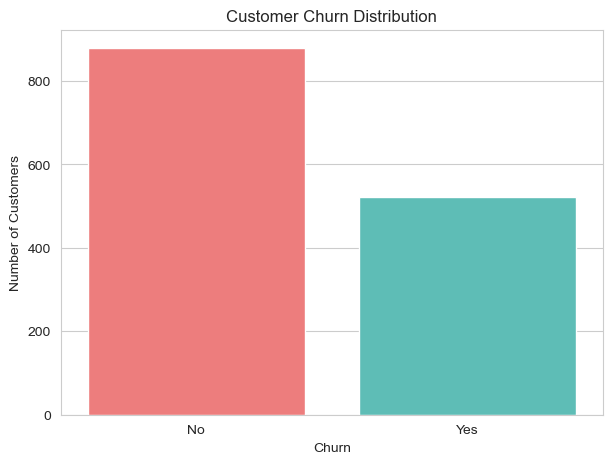

In [66]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    palette=["#FF6B6B", "#4ECDC4"])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

## Cleaning Text Columns

Some text values may contain extra spaces or inconsistent capitalization.

I will standardize the `Gender`, `City`, and `Contract` columns by removing 
extra spaces and converting the text to lowercase.

In [69]:
text_columns = [
    "Gender",
    "City",
    "Contract"
]

for col in text_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

## Checking Cleaned Text Values

I will check the unique values after cleaning to make sure the formatting 
has become more consistent.

In [72]:
for col in text_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Gender
Gender
female    732
male      669
Name: count, dtype: Int64

 City
City
mumbai       219
chennai      184
hyderabad    183
delhi        172
pune         166
ahmedabad    161
bengaluru    159
kolkata      157
Name: count, dtype: Int64

 Contract
Contract
month-to-month    784
one year          346
two year          271
Name: count, dtype: Int64


## Cleaning Total Charges
The `Total Charges` column should contain numerical values, but some records 
contain blank or whitespace values.
I will first investigate these values before converting the column to numeric.

In [75]:
print(df["Total Charges"].head(20))
print("\nData type:", df["Total Charges"].dtype)

0     1207.59
1      774.39
2      737.35
3      134.52
4       112.6
5       64.33
6      614.45
7      678.59
8     5590.26
9      208.02
10           
11      591.4
12    7134.43
13     659.35
14     5569.6
15     488.83
16     396.33
17     723.64
18     519.56
19     2802.5
Name: Total Charges, dtype: object

Data type: object


## Checking Blank Total Charges

I will check how many records contain blank or whitespace values in 
`Total Charges`.

In [80]:
blank_total_charges = (
    df["Total Charges"]
    .astype(str)
    .str.strip()
    .eq(""))
print(
    "Blank Total Charges:",
    blank_total_charges.sum())

Blank Total Charges: 36


In [84]:
# Replace blank values with NaN

df["Total Charges"] = df["Total Charges"].replace(r"^\s*$", np.nan, regex=True)
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Missing Total Charges:", df["Total Charges"].isnull().sum())

Missing Total Charges: 36


In [86]:
# Fill missing Total Charges with the median

median_total_charges = df["Total Charges"].median()
df["Total Charges"] = df["Total Charges"].fillna(median_total_charges)
print("Missing Total Charges after filling:",
      df["Total Charges"].isnull().sum())

Missing Total Charges after filling: 0


## Converting Total Charges to Numeric

After investigating the column, I will convert `Total Charges` into a numeric 
format.
Values that cannot be converted will become missing values and will be handled 
later during preprocessing.

In [91]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce")
print(df["Total Charges"].dtype)

float64


## Handling Negative Tenure
Tenure represents the number of months a customer has been with the company.
A negative tenure value is not logically possible, so these values will be 
treated as invalid and replaced with missing values.
Later the missing values will be handled using median imputation.

In [96]:
negative_tenure = (
    df["Tenure (Months)"]< 0
).sum()
print(
    "Negative tenure values:",
    negative_tenure)

Negative tenure values: 5


In [100]:
## Replace Negative Tenure
df.loc[
    df["Tenure (Months)"] < 0,
    "Tenure (Months)"
] = np.nan

In [102]:
print(
    "Negative tenure remaining:",
    (df["Tenure (Months)"] < 0).sum())

Negative tenure remaining: 0


In [ ]:
## Missing Values After Cleaning
Some missing values are expected after converting invalid values into missing 
values.
I will check the entitre dataset again before creating the machine learning pipeline.

In [104]:
missing_after_cleaning = df.isnull().sum()

missing_after_cleaning[
    missing_after_cleaning > 0
].sort_values(
    ascending=False
)

Tenure (Months)    5
dtype: int64

In [112]:
# Calculate median tenure
median_tenure = df["Tenure (Months)"].median()
# Fill missing tenure values
df["Tenure (Months)"] = df["Tenure (Months)"].fillna(median_tenure)
print("Median Tenure:", median_tenure)

Median Tenure: 16.0


In [114]:
missing_after_cleaning = df.isnull().sum()

missing_after_cleaning[
    missing_after_cleaning > 0
].sort_values(
    ascending=False
)

Series([], dtype: int64)

In [116]:
print("Missing Tenure values:",
      df["Tenure (Months)"].isnull().sum())

Missing Tenure values: 0


# Task 3: Feature Engineering and Train/Test Split

Feature engineering means creating new variables from the existing data.

I will create a few simple features that may help the model understand 
customer behavior better.

The features will include:

- Addon Count
- Average Monthly Spend
- New Customer

## Addon Count
I will count how many additional services each customer has subscribed to.
This may give an idea of how engaged a customer is with the company's services.

In [122]:
addon_columns = [
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"]
df["Addon Count"] = (
    df[addon_columns]
    .eq("Yes")
    .sum(axis=1))
df["Addon Count"].head()

0    3
1    2
2    2
3    3
4    3
Name: Addon Count, dtype: int64

In [124]:
df

,Customer ID,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn,Addon Count
0,CUST-10410,female,No,No,No,delhi,12.0,Yes,Yes,Fiber Optic,...,No,No,Yes,month-to-month,Yes,Bank Transfer,101.43,1207.59,No,3
1,CUST-10511,female,Yes,No,No,chennai,10.0,Yes,Yes,DSL,...,No,No,No,month-to-month,Yes,Credit Card,79.12,774.39,No,2
2,CUST-10346,female,No,Yes,Yes,chennai,7.0,Yes,No,Fiber Optic,...,No,No,Yes,month-to-month,Yes,Electronic Check,107.81,737.35,Yes,2
3,CUST-10055,male,Yes,No,Yes,mumbai,1.0,Yes,No,Fiber Optic,...,No,Yes,Yes,one year,Yes,Mailed Check,131.53,134.52,No,3
4,CUST-10973,male,No,No,No,mumbai,1.0,Yes,Yes,Fiber Optic,...,Yes,No,Yes,one year,Yes,Credit Card,110.43,112.60,No,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1411,CUST-10928,female,No,No,No,hyderabad,60.0,Yes,No,No Internet,...,No Internet Service,No Internet Service,No Internet Service,one year,No,Electronic Check,33.36,2005.79,Yes,0
1412,CUST-11318,female,No,No,No,mumbai,25.0,Yes,Yes,Fiber Optic,...,No,No,No,two year,Yes,Mailed Check,106.63,2677.21,Yes,3
1413,CUST-10236,male,Yes,No,No,kolkata,1.0,Yes,Yes,Fiber Optic,...,Yes,No,Yes,month-to-month,Yes,Electronic Check,122.47,142.17,No,4
1414,CUST-10608,male,No,Yes,Yes,mumbai,41.0,Yes,No,Fiber Optic,...,No,No,No,month-to-month,Yes,Mailed Check,108.68,4441.71,Yes,1


## Average Monthly Spend

I will create a new feature by dividing the customer's total charges by 
their tenure.
This gives an additional view of the customer's average spending.

In [127]:
df["Average Monthly Spend"] = (
    df["Total Charges"] /
    df["Tenure (Months)"].replace(0, np.nan))
df["Average Monthly Spend"] = (
    df["Average Monthly Spend"]
    .replace([np.inf, -np.inf], np.nan))
df[
    [
    "Total Charges",
    "Tenure (Months)",
    "Average Monthly Spend"]].head()

,Total Charges,Tenure (Months),Average Monthly Spend
0,1207.59,12.0,100.632500
1,774.39,10.0,77.439000
2,737.35,7.0,105.335714
3,134.52,1.0,134.520000
4,112.60,1.0,112.600000


In [129]:
df

,Customer ID,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,...,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn,Addon Count,Average Monthly Spend
0,CUST-10410,female,No,No,No,delhi,12.0,Yes,Yes,Fiber Optic,...,No,Yes,month-to-month,Yes,Bank Transfer,101.43,1207.59,No,3,100.632500
1,CUST-10511,female,Yes,No,No,chennai,10.0,Yes,Yes,DSL,...,No,No,month-to-month,Yes,Credit Card,79.12,774.39,No,2,77.439000
2,CUST-10346,female,No,Yes,Yes,chennai,7.0,Yes,No,Fiber Optic,...,No,Yes,month-to-month,Yes,Electronic Check,107.81,737.35,Yes,2,105.335714
3,CUST-10055,male,Yes,No,Yes,mumbai,1.0,Yes,No,Fiber Optic,...,Yes,Yes,one year,Yes,Mailed Check,131.53,134.52,No,3,134.520000
4,CUST-10973,male,No,No,No,mumbai,1.0,Yes,Yes,Fiber Optic,...,No,Yes,one year,Yes,Credit Card,110.43,112.60,No,3,112.600000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1411,CUST-10928,female,No,No,No,hyderabad,60.0,Yes,No,No Internet,...,No Internet Service,No Internet Service,one year,No,Electronic Check,33.36,2005.79,Yes,0,33.429833
1412,CUST-11318,female,No,No,No,mumbai,25.0,Yes,Yes,Fiber Optic,...,No,No,two year,Yes,Mailed Check,106.63,2677.21,Yes,3,107.088400
1413,CUST-10236,male,Yes,No,No,kolkata,1.0,Yes,Yes,Fiber Optic,...,No,Yes,month-to-month,Yes,Electronic Check,122.47,142.17,No,4,142.170000
1414,CUST-10608,male,No,Yes,Yes,mumbai,41.0,Yes,No,Fiber Optic,...,No,No,month-to-month,Yes,Mailed Check,108.68,4441.71,Yes,1,108.334390


## New Customer Feature
Customers who have been with the company for a short period may behave 
differently from long-term customers.
I will create a feature that identifies customers with six months or less 
of tenure.

In [134]:
df["New Customer"] = np.where(
    df["Tenure (Months)"] <=6,
    "Yes",
    "No")
df["New Customer"].value_counts()

New Customer
No     1051
Yes     350
Name: count, dtype: int64

In [136]:
df

,Customer ID,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn,Addon Count,Average Monthly Spend,New Customer
0,CUST-10410,female,No,No,No,delhi,12.0,Yes,Yes,Fiber Optic,...,Yes,month-to-month,Yes,Bank Transfer,101.43,1207.59,No,3,100.632500,No
1,CUST-10511,female,Yes,No,No,chennai,10.0,Yes,Yes,DSL,...,No,month-to-month,Yes,Credit Card,79.12,774.39,No,2,77.439000,No
2,CUST-10346,female,No,Yes,Yes,chennai,7.0,Yes,No,Fiber Optic,...,Yes,month-to-month,Yes,Electronic Check,107.81,737.35,Yes,2,105.335714,No
3,CUST-10055,male,Yes,No,Yes,mumbai,1.0,Yes,No,Fiber Optic,...,Yes,one year,Yes,Mailed Check,131.53,134.52,No,3,134.520000,Yes
4,CUST-10973,male,No,No,No,mumbai,1.0,Yes,Yes,Fiber Optic,...,Yes,one year,Yes,Credit Card,110.43,112.60,No,3,112.600000,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1411,CUST-10928,female,No,No,No,hyderabad,60.0,Yes,No,No Internet,...,No Internet Service,one year,No,Electronic Check,33.36,2005.79,Yes,0,33.429833,No
1412,CUST-11318,female,No,No,No,mumbai,25.0,Yes,Yes,Fiber Optic,...,No,two year,Yes,Mailed Check,106.63,2677.21,Yes,3,107.088400,No
1413,CUST-10236,male,Yes,No,No,kolkata,1.0,Yes,Yes,Fiber Optic,...,Yes,month-to-month,Yes,Electronic Check,122.47,142.17,No,4,142.170000,Yes
1414,CUST-10608,male,No,Yes,Yes,mumbai,41.0,Yes,No,Fiber Optic,...,No,month-to-month,Yes,Mailed Check,108.68,4441.71,Yes,1,108.334390,No


## Preparing Features and Target

The `Churn` column will be used as the target variable.

`Customer ID` will be removed because it is only an identifier and does not 
provide useful information for predicting churn.

In [141]:
X = df.drop(
    columns=[
        "Churn",
        "Customer ID"])
y = df["Churn"].map({
    "No": 0,
    "Yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1401, 23)
y shape: (1401,)


In [145]:
 X

,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,Online Security,...,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Addon Count,Average Monthly Spend,New Customer
0,female,No,No,No,delhi,12.0,Yes,Yes,Fiber Optic,No,...,No,Yes,month-to-month,Yes,Bank Transfer,101.43,1207.59,3,100.632500,No
1,female,Yes,No,No,chennai,10.0,Yes,Yes,DSL,No,...,No,No,month-to-month,Yes,Credit Card,79.12,774.39,2,77.439000,No
2,female,No,Yes,Yes,chennai,7.0,Yes,No,Fiber Optic,No,...,No,Yes,month-to-month,Yes,Electronic Check,107.81,737.35,2,105.335714,No
3,male,Yes,No,Yes,mumbai,1.0,Yes,No,Fiber Optic,Yes,...,Yes,Yes,one year,Yes,Mailed Check,131.53,134.52,3,134.520000,Yes
4,male,No,No,No,mumbai,1.0,Yes,Yes,Fiber Optic,No,...,No,Yes,one year,Yes,Credit Card,110.43,112.60,3,112.600000,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1411,female,No,No,No,hyderabad,60.0,Yes,No,No Internet,No Internet Service,...,No Internet Service,No Internet Service,one year,No,Electronic Check,33.36,2005.79,0,33.429833,No
1412,female,No,No,No,mumbai,25.0,Yes,Yes,Fiber Optic,Yes,...,No,No,two year,Yes,Mailed Check,106.63,2677.21,3,107.088400,No
1413,male,Yes,No,No,kolkata,1.0,Yes,Yes,Fiber Optic,Yes,...,No,Yes,month-to-month,Yes,Electronic Check,122.47,142.17,4,142.170000,Yes
1414,male,No,Yes,Yes,mumbai,41.0,Yes,No,Fiber Optic,No,...,No,No,month-to-month,Yes,Mailed Check,108.68,4441.71,1,108.334390,No


In [147]:
y

0       0
1       0
2       1
3       0
4       0
       ..
1411    1
1412    1
1413    0
1414    1
1415    0
Name: Churn, Length: 1401, dtype: int64

## Identifying Numerical and Categorical Features

Numerical and categorical columns need different preprocessing methods.

Numerical columns will be imputed and scaled.

Categorical columns will be imputed and one-hot encoded.

In [150]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()
print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Tenure (Months)', 'Monthly Charges', 'Total Charges', 'Addon Count', 'Average Monthly Spend']

Categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'City', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'New Customer']


## Train/Test Split

I will split the data into 80% training data and 20% testing data.
Stratification will be used so that the proportion of churned and non-churned 
customers remains similar in both datasets.

In [153]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1120, 23)
Testing data: (281, 23)


## Data Preprocessing

For numerical columns, missing values will be filled using the median and 
the values will be standardized.
For categorical columns, missing values will be filled using the most frequent 
value and then converted into numerical form using one-hot encoding.
The preprocessing will be placed inside a pipeline to avoid data leakage.

In [162]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [164]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
        "categorical",
        categorical_pipeline,
        categorical_features
        )
    ]
)

# Task 4: Model Building

I will build two classification models:
1. Logistic Regression
2. Random Forest
Using two different models allows us to compare their performance and select 
the model that is more suitable for this churn prediction problem.

## Logistic Regression

Logistic Regression is a simple and commonly used classification algorithm.
it is useful as a baseline model and can also help us understand the relationship 
between the features and churn.

In [168]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

## Random Forest
Random Forest is an ensemble model made up of multiple decision trees.
It can handle nonlinear relationships and interactions between different 
features, which can be useful for customer churn prediction.

In [171]:
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1))])

## Cross-Validation

I will use 5-fold Stratified Cross-Validation on the training data.
This helps us get a more reliable idea of how the models perform before 
evaluating them on the final test data.
The test data will not be used during model selection.

In [174]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

## logistic crossvalidation

In [176]:
logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

logistic_cv_results = {
    metric: logistic_cv[f"test_{metric}"].mean()
    for metric in scoring
}

pd.Series(logistic_cv_results)

accuracy     0.651786
precision    0.551684
recall       0.371830
f1           0.443325
roc_auc      0.674857
dtype: float64

## Random forest crossvalidation

In [178]:
rf_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = {
    metric: rf_cv[f"test_{metric}"].mean()
    for metric in scoring
}

pd.Series(rf_cv_results)

accuracy     0.643750
precision    0.540292
recall       0.311847
f1           0.394511
roc_auc      0.651742
dtype: float64

## Comparing Cross-Validation Results

The following table compares the average cross-validation performance of 
the two models.

In [183]:
cv_results = pd.DataFrame({
    "Logistic Regression": logistic_cv_results,
    "Random Forest": rf_cv_results
}).T

cv_results.round(3)

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.652,0.552,0.372,0.443,0.675
Random Forest,0.644,0.540,0.312,0.395,0.652


## Training the Models

After completing cross-validation, I will train both models on the complete 
training dataset.

The test dataset will remain untouched until the final evaluation.

In [186]:
logistic_model.fit(
    X_train,
    y_train
)

random_forest_model.fit(
    X_train,
    y_train

)

print("Both models trained successfully.")

Both models trained successfully.


# Task 5: Model Evaluation

Now I will evaluate both models on the test dataset.

The following metrics will be used:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
Accuracy alone is not enough because the churn classes are not perfectly balanced.

## Pridiction

In [190]:
logistic_predictions = logistic_model.predict(X_test)

rf_predictions = random_forest_model.predict(X_test)

logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1])

rf_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1])

## Evaluation Function
I will create one function to calculate all the required evaluation metrics 
for each model.

In [193]:
def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities
):
    
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            probabilities
        )
    }

## Evaluate models

In [195]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions,
    logistic_probabilities
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)

results = pd.DataFrame([
    logistic_results,
    rf_results
])

results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.651,0.551,0.362,0.437,0.659
1,Random Forest,0.655,0.569,0.314,0.405,0.644


## Classification Reports
The classification reports provide a detailed view of Precision, Recall, 
F1-score and support for both classes.

In [199]:
print("LOGISTIC REGRESSION")
print(
    classification_report(
        y_test,
        logistic_predictions))
print("\n" + "="*50 + "\n")
print("RANDOM FOREST")
print(
    classification_report(
        y_test,
        rf_predictions))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.68      0.82      0.75       176
           1       0.55      0.36      0.44       105

    accuracy                           0.65       281
   macro avg       0.62      0.59      0.59       281
weighted avg       0.63      0.65      0.63       281



RANDOM FOREST
              precision    recall  f1-score   support

           0       0.68      0.86      0.76       176
           1       0.57      0.31      0.40       105

    accuracy                           0.65       281
   macro avg       0.62      0.59      0.58       281
weighted avg       0.64      0.65      0.63       281



## Selecting the Best Model

I will compare the models using the evaluation metrics.
For this problem Recall F1-score and ROC-AUC are especially important because 
the business wants to identify customers who may leave.
The final model will be selected based on the overall performance rather than 
accuracy alone.

In [203]:
best_row = results.loc[
    results["ROC-AUC"].idxmax()
]

best_model_name = best_row["Model"]

if best_model_name == "Random Forest":
    best_model = random_forest_model
    best_predictions = rf_predictions
    best_probabilities = rf_probabilities
else:
    best_model = logistic_model
    best_predictions = logistic_predictions
    best_probabilities = logistic_probabilities

print("Selected Model:", best_model_name)

Selected Model: Logistic Regression


## Confusion Matrix
The confusion matrix helps us understand how many customers were correctly 
and incorrectly classified.
False negatives are especially important in this project because they represent 
customers who actually churned but were not identified by the model.

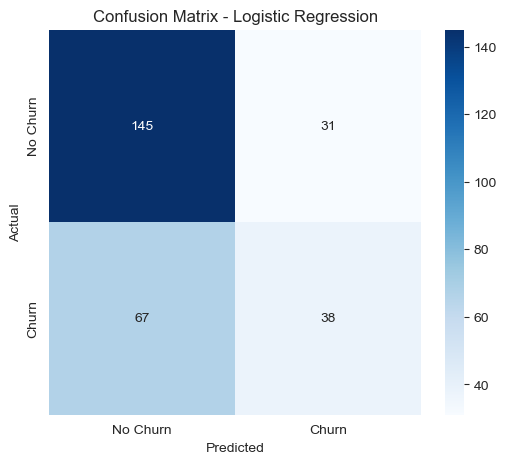

In [206]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Churn",
        "Churn"
    ],
    yticklabels=[
        "No Churn",
        "Churn"
    ]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## ROC Curve

The ROC curve shows how well the model can separate customers who churn 
from customers who do not churn.
The ROC-AUC value gives an overall measure of the model's ability to distinguish 
between the two classes.

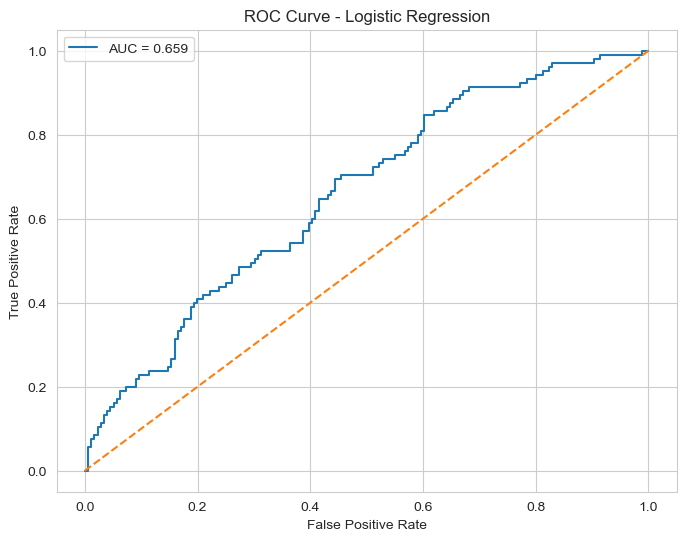

In [209]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probabilities
)

auc_score = roc_auc_score(
    y_test,
    best_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_score:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - {best_model_name}"
)

plt.legend()

plt.show()

# Task 6: Business Insights and Recommendations

In this section, I will look at the important features from the final model 
and use the results to understand which types of customers are more likely 
to churn.
The aim is to turn the machine learning results into practical actions that 
the company's retention team can use.

## Feature Importance

Feature importance helps us understand which variables are most useful for 
the model when predicting customer churn.
For Random Forest, I will use feature importance scores.
For Logistic Regression, I will look at the model coefficients.

In [213]:
feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out())

print("Number of model features:", len(feature_names))

Number of model features: 58


In [215]:
if best_model_name == "Random Forest":

    top_features = (
        feature_importance
        .head(15)
        .sort_values("Importance")
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title(
        "Top 15 Important Features"
    )

    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

## Churn Rate by Contract Type
Contract type may have an important relationship with customer churn.
I will calculate the churn percentage for each contract type.

In [220]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(
        lambda x: (
            x == "Yes"
        ).mean() * 100
    )
    .sort_values(
        ascending=False
    )
)
contract_churn.round(2)

Contract
month-to-month    45.92
one year          32.66
two year          18.08
Name: Churn, dtype: float64

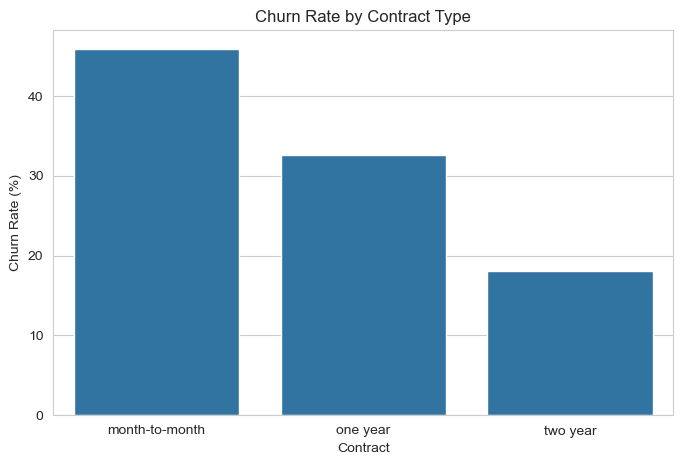

In [222]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")

plt.xlabel("Contract")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

## Churn Rate by Tenure
I will divide customers into different tenure groups to see whether newer 
or longer-term customers have different churn rates.

In [229]:
df["Tenure Group"] = pd.cut(
    df["Tenure (Months)"],
    bins=[
        -1,
        6,
        12,
        24,
        48,
        72,
        np.inf
    ],
    labels=[
        "0-6",
        "7-12",
        "13-24",
        "25-48",
        "49-72",
        "72+"
    ]
)

tenure_churn = (
    df.groupby(
        "Tenure Group",
        observed=True
    )["Churn"]
    .apply(
        lambda x: (
            x == "Yes"
        ).mean() * 100
    )
)

tenure_churn.round(2)

Tenure Group
0-6      54.86
7-12     33.77
13-24    34.22
25-48    32.81
49-72    22.11
Name: Churn, dtype: float64

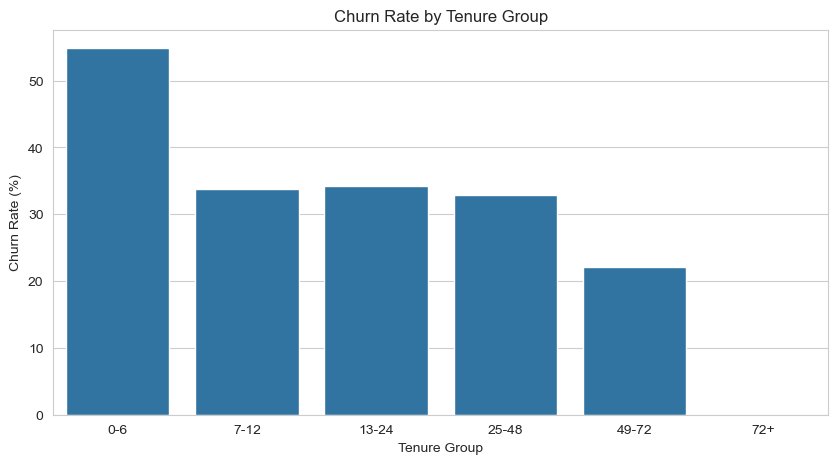

In [231]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title("Churn Rate by Tenure Group")

plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

## Churn Rate by Payment Method

I will also compare churn rates across different payment methods to see 
whether some payment groups have higher churn.

In [236]:
payment_churn = (
    df.groupby("Payment Method")["Churn"]
    .apply(
        lambda x: (
            x == "Yes"
        ).mean() * 100
    )
    .sort_values(
        ascending=False
    )
)

payment_churn.round(2)

Payment Method
Electronic Check    42.98
Credit Card         37.61
Bank Transfer       35.23
Mailed Check        33.13
Name: Churn, dtype: float64

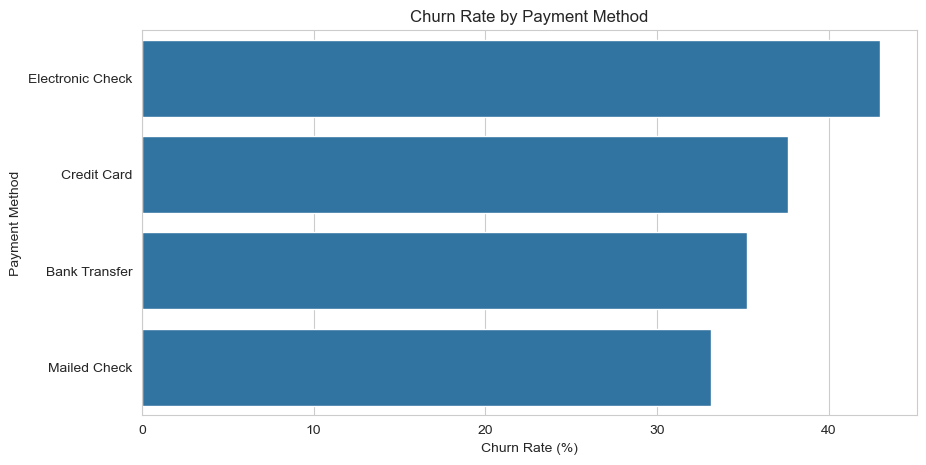

In [238]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.values,
    y=payment_churn.index
)

plt.title("Churn Rate by Payment Method")

plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")

plt.show()

## Identifying High-Risk Customers

The model provides a churn probability for each customer.
I will use these probabilities to group customers into low-, medium-, and 
high-risk categories.
This can help the retention team focus on customers who need attention first.

In [243]:
risk_data = X_test.copy()

risk_data["Actual Churn"] = y_test.values

risk_data["Churn Probability"] = (
    best_probabilities
)

risk_data["Risk Level"] = pd.cut(
    risk_data["Churn Probability"],
    bins=[
        -np.inf,
        0.30,
        0.60,
        np.inf
    ],
    labels=[
        "Low",
        "Medium",
        "High"
    ]
)

risk_data.sort_values(
    "Churn Probability",
    ascending=False
).head(20)

,Gender,Senior Citizen,Partner,Dependents,City,Tenure (Months),Phone Service,Multiple Lines,Internet Service,Online Security,...,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Addon Count,Average Monthly Spend,New Customer,Actual Churn,Churn Probability,Risk Level
1037,female,No,Yes,Yes,kolkata,5.0,Yes,No,DSL,No,...,No,Electronic Check,87.390,425.82,2,85.164000,Yes,0,0.778632,High
680,male,No,Yes,No,chennai,1.0,Yes,Yes,Fiber Optic,No,...,No,Electronic Check,99.270,90.01,2,90.010000,Yes,1,0.770279,High
573,female,No,Yes,No,hyderabad,3.0,Yes,Yes,Fiber Optic,No,...,No,Credit Card,101.700,302.14,3,100.713333,Yes,1,0.758594,High
828,female,No,Yes,No,delhi,0.0,Yes,Yes,Fiber Optic,No,...,No,Electronic Check,92.665,1303.66,3,NaN,Yes,1,0.752274,High
649,female,Yes,Yes,No,bengaluru,2.0,Yes,Yes,Fiber Optic,No,...,Yes,Mailed Check,110.660,205.38,2,102.690000,Yes,1,0.743610,High
252,female,Yes,Yes,Yes,mumbai,5.0,Yes,No,DSL,No,...,Yes,Bank Transfer,72.950,364.96,3,72.992000,Yes,1,0.737731,High
869,female,No,Yes,Yes,ahmedabad,6.0,Yes,Yes,Fiber Optic,Yes,...,Yes,Credit Card,102.340,619.79,2,103.298333,Yes,1,0.730400,High
861,male,No,Yes,No,kolkata,4.0,Yes,No,DSL,No,...,Yes,Electronic Check,59.740,234.86,1,58.715000,Yes,0,0.730270,High
1275,male,No,Yes,No,delhi,0.0,Yes,Yes,Fiber Optic,Yes,...,Yes,Electronic Check,87.780,1303.66,2,NaN,Yes,1,0.723634,High
625,female,No,Yes,Yes,bengaluru,0.0,Yes,No,Fiber Optic,No,...,Yes,Mailed Check,118.330,1303.66,2,NaN,Yes,1,0.717285,High


In [245]:
risk_summary = (
    risk_data["Risk Level"]
    .value_counts()
)

risk_summary

Risk Level
Medium    141
Low       104
High       36
Name: count, dtype: int64

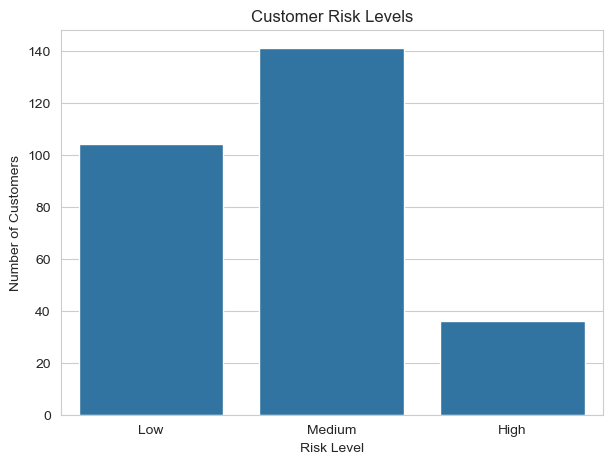

In [247]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=risk_data,
    x="Risk Level",
    order=[
        "Low",
        "Medium",
        "High"
    ]
)

plt.title("Customer Risk Levels")

plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")

plt.show()

# Business Insights

Based on the analysis, the following points can be considered:

- Customers with a higher predicted probability of churn should be given 
  priority by the retention team.
- Contract type can be considered when designing retention campaigns.
- New customers may need additional support during their early months.
- Customers with higher churn risk can receive targeted offers instead of 
  sending the same offer to every customer.
- The important features from the model can help the business understand 
  which customer characteristics should be monitored.

# Recommendation

Based on the analysis, the company should focus on customers who have a high 
predicted probability of churn.

A useful strategy would be to target high-risk customers with personalized 
offers, better customer support, or suitable contract-upgrade options.

Special attention can be given to customers in their early months and customers 
with contract types that show higher churn in the analysis.

The exact customer segment and offer should be based on the churn rates and 
model results obtained from the analysis.

# Conclusion

In this project, I analyzed customer data and built machine learning models 
to predict customer churn.

The data was first explored and cleaned by handling duplicate records, missing 
values, inconsistent text, invalid tenure values, and billing-related issues.

I then created new features and prepared the data for machine learning.

Two classification models, Logistic Regression and Random Forest, were trained 
and compared using cross-validation.

The models were evaluated using Accuracy, Precision, Recall, F1-score, and 
ROC-AUC. The final model was selected based on its overall performance.

The results can help the company identify customers who are more likely to 
churn and take action before they leave.

Overall, the project shows how machine learning can be used not only to make 
predictions but also to support practical customer-retention decisions.